<a href="https://colab.research.google.com/github/Radiat09/colab/blob/main/ML_Assignment_01_ans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ML Assignment -1

Dataset: Titanic Dataset (titanic_data_updated.csv)

Total Marks: 100

Email: radiathossainr@gmail.com

Name: MD Radiat Hossain Ridoy



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Question 1 (10 Marks)
Load the Titanic dataset and display:
- Dataset shape
- First 10 rows
- 5 random samples

In [2]:
from tabulate import tabulate

df = pd.read_csv("/content/titanic_data_updated.csv")

print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")

print("--- Head (Top 10) ---")
print(tabulate(df.head(10).to_dict("records"), headers="keys", tablefmt="psql", showindex="always"))

print("\n--- Random Sample (5) ---")
print(tabulate(df.sample(5).to_dict("records"), headers="keys", tablefmt="psql", showindex="always"))

Shape: 891 rows × 12 columns

--- Head (Top 10) ---
+----+---------------+------------+----------+-----------------------------------------------------+--------+-------+---------+---------+------------------+---------+---------+------------+
|    |   PassengerId | Survived   | Pclass   | Name                                                | Sex    |   Age |   SibSp |   Parch | Ticket           |    Fare | Cabin   | Embarked   |
|----+---------------+------------+----------+-----------------------------------------------------+--------+-------+---------+---------+------------------+---------+---------+------------|
|  0 |             1 | no         | third    | Braund, Mr. Owen Harris                             | male   |    22 |       1 |       0 | A/5 21171        |  7.25   | nan     | S          |
|  1 |             2 | yes        | first    | Cumings, Mrs. John Bradley (Florence Briggs Thayer) | female |    38 |       1 |       0 | PC 17599         | 71.2833 | C85     | C          

# Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
- Finding total missing values
- Finding duplicate rows
- Removing duplicate rows permanently

In [3]:
print("=== DataFrame Info ===")
print(df.info())

print("\n=== Missing Values per Column ===")
print(df.isna().sum())
print("Total missing values:", int(df.isna().sum().sum()))

print("\n=== Duplicate Rows Before Removal ===")
print(df.duplicated().value_counts())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("\n=== Shape After Removing Duplicates ===")
print(df.shape)

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
None

=== Missing Values per Column ===
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare      

# Question 3 (10 Marks)
Perform statistical profiling of the Titanic dataset and display:
- Dataset information
- Statistical summary of numerical columns

Also write 2 observations from the output.


In [4]:

# 1. Dataset Information
print("=== Dataset Info ===")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")
df.info()

# 2. Statistical Summary of Numerical Columns
print("\n=== Statistical Summary (Numerical Columns) ===")
print(df.describe())

=== Dataset Info ===
Shape: 891 rows × 12 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB

=== Statistical Summary (Numerical Columns) ===
       PassengerId         Age       SibSp       Parch        Fare
count   891.000000  714.000000  891.000000  891.000000  891.000000
mean    44

## Observations

Many missing values in data:

Cabin has 204 non-null values meaning there are 77.1% missing values from the total number of 891. Age has 714 non-null values meaning there are 177 missing values (19.9%). Embarked has only 2 missing values (889 non-null). Therefore, Cabin column may need to be removed completely or highly engineered. Age and Embarked must be filled using imputation techniques.

Skewed data and outliers in Fare:

The mean fare given in the summary statistics is 32.20 (32.204208) which is significantly higher than the median fare (50%) of 14.45 (14.454200). The standard deviation is also very large at 49.69 (49.693429). Compared to the 3rd quartile (75 th percentile) value of 31.00, the maximum value is extremely large, at 512.33 (512.329200), indicating that the distribution of fares is right skewed. There are extreme outliers on the higher end of the distribution. However, it appears that the majority of passengers had low fares.

# Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
- Creating a countplot
- Calculating percentage distribution
- Creating a pie chart

Write 2 insights from the analysis.

<Axes: xlabel='Survived', ylabel='count'>

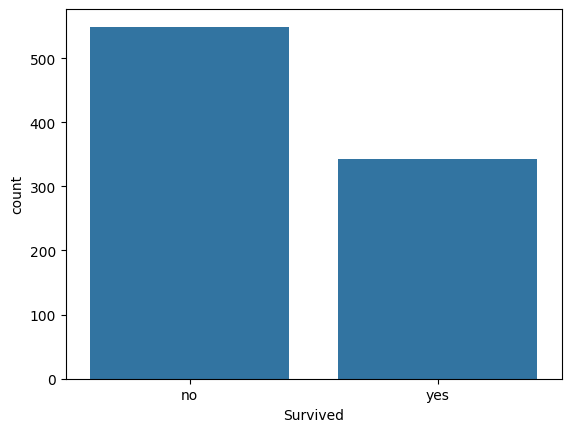

In [6]:
# Creating a countplot
sns.countplot(data=df, x="Survived")

In [16]:
# Calculating percentage distribution
survived_count =  (df['Survived'].value_counts() / len(df))  * 100

survived_count

,count
Survived,
no,61.616162
yes,38.383838


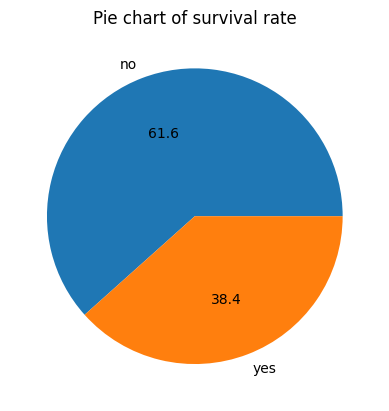

In [17]:
# Creating a pie chart

survived_label = df['Survived'].unique()

plt.pie(survived_count, labels = survived_label, autopct="%1.1f")
plt.title('Pie chart of survival rate')
plt.show()

## Write 2 insights from the analysis.
We can see that the majority of people did not survive. There are 61.6% (549 passengers) in the category for ‘no’ and only 38.4% (342 passengers) in the category for ‘yes’. This is a difference of around 23.2%. The 3:2 ratio of people who didn’t survive to those who did indicates a moderate class imbalance within Survived. This means models trained on this data will be given more negative cases than positive cases.

# Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
- Creating a histogram
- Creating a KDE plot

Write 2 observations from the plots.


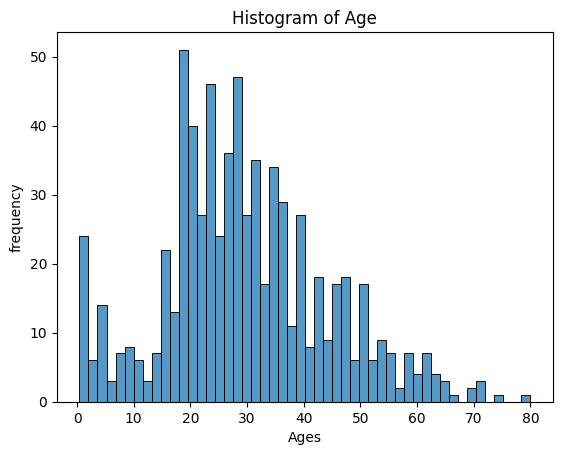

In [20]:
# Creating a histogram

sns.histplot(df['Age'],bins=50)

plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('frequency')

plt.show()

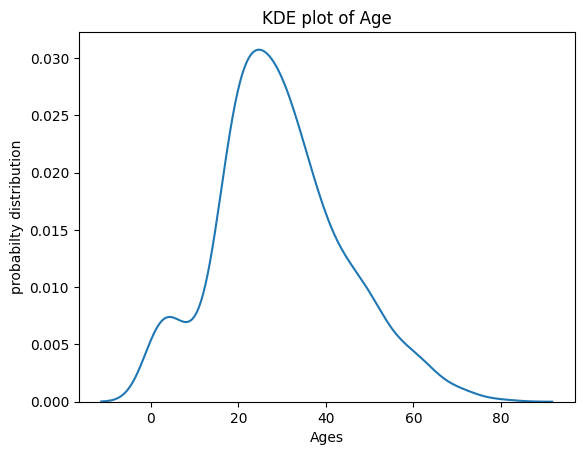

In [21]:
# Creating a KDE plot

sns.kdeplot(df['Age'])
plt.title('KDE plot of Age')
plt.xlabel('Ages')
plt.ylabel('probabilty distribution')

plt.show()

## Write 2 observations from the plots.


The data shows skewness to the right. Most passengers are young adults (peak between 20-30s). Within the histogram, the most frequent age is between the highest bin which contains around 50 people. This aligns with the KDE plot, where the peak density occurs just above 0.030 at age 25. As people get older (>60), there are fewer people present, until around age 80. There appears to be a smaller peak between infancy/early childhood (between 0-5). In the histogram, there is a relatively high frequency of people with age near 24, and in the KDE plot there is a small peak (0.007) at age 0. However, people of age 10-15 are less frequent.

# Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.

Also calculate normalized survival ratios using groupby().

Write 2 insights from the analysis.


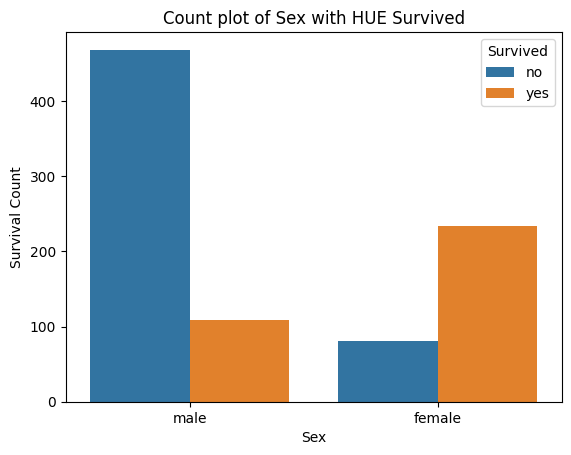

In [24]:
# Creating a Count plot with Hue

sns.countplot(x=df['Sex'],hue=df['Survived'])
plt.title('Count plot of Sex with HUE Survived')
plt.xlabel('Sex')
plt.ylabel("Survival Count")

plt.show()

In [26]:
# calculate normalized survival ratios using groupby()

gender_split = df.groupby("Sex")["Survived"].value_counts(normalize=True)
gender_split

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64

## Write 2 insights from the analysis.
Although male passengers outnumber females overall in the count plot, **74.20%** (`0.742038`) of females survived compared to just **18.89%** (`0.188908`) of males—a survival gap of over 55 percentage points. Conversely, **81.11%** (`0.811092`) of males did not survive versus **25.80%** (`0.257962`) of females, reflecting evacuation priorities ("women and children first") and confirming that `Sex` is a strong predictive feature for `Survived`.

# Question 7 (10 Marks)

Create a barplot showing the relationship between Pclass and Fare.

Write 2 observations from the visualization.


<Axes: xlabel='Pclass', ylabel='Fare'>

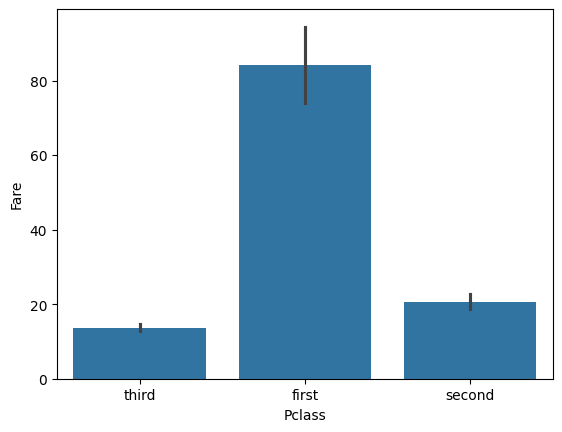

In [27]:
sns.barplot(x=df['Pclass'], y=df['Fare'])

## Write 2 observations from the visualization.

The barplot shows a huge jump in average ticket price for `first` class (around **84**) compared to `second` class (around **21**) and `third` class (around **14**), meaning first-class passengers paid almost four times more than second-class and six times more than third-class passengers. Additionally, the much taller error bar on `first` class indicates significantly bigger variation in fare prices within first class, where `second` and `third` class fares remain at lower levels.

# Question 8 (10 Marks)

Create a KDE plot to compare the Age distribution of survived and non-survived passengers.

Write 2 insights from the graph.


<Axes: xlabel='Age', ylabel='Density'>

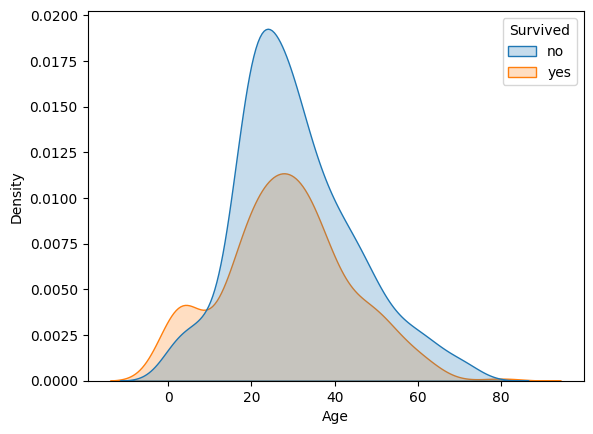

In [31]:
sns.kdeplot(data=df,x="Age", hue="Survived",fill=True)

## Write 2 insights from the graph.

From the KDE plots of Age across Survived,

We can see that:

There were many more people who did not survive within the young adult age range. The ‘no’ group has a significantly higher peak in density (~ 0.019 at age = 23-24) than the ‘yes’ group (~0.011 at age = 28-29). Therefore, we can observe that there were a lot of people in the young adult age range who did not survive.

There were relatively more people who survived within the very young age range. Within the lower age range (age < 10, with a peak near age = 3-5, ~0.004), the density of survivors (‘yes’, orange) is clearly higher than density of people who did not survive (‘no’, blue). Thus, compared to higher age ranges where the density of ‘no’ is greater, we can observe that there were relatively more survivors in the very young age range.

# Question 9 (10 Marks)
Perform feature engineering and train-test split by:
- Dropping PassengerId, Name, and Ticket columns
- Separating features (X) and target (y)
- Splitting the dataset using test_size=0.2 and random_state=42

Display the shapes of train and test datasets.


In [35]:
# remove unnessesary columns (Dropping PassengerId, Name, and Ticket columns)
df.drop(["PassengerId","Name","Ticket"],axis=1, inplace=True)

KeyError: "['PassengerId', 'Name', 'Ticket'] not found in axis"

In [34]:
# Separating features (X) and target (y)
x = df.drop(["Survived"], axis=1)

y = df['Survived']

display(x)
y

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,NaN,S
887,first,female,19.0,0,0,30.0000,B42,S
888,third,female,NaN,1,2,23.4500,NaN,S
889,first,male,26.0,0,0,30.0000,C148,C


,Survived
0,no
1,yes
2,yes
3,yes
4,no
...,...
886,no
887,yes
888,no
889,yes


In [36]:
# Splitting the dataset using test_size=0.2 and random_state=42
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [39]:
# Display the shapes of train and test datasets.

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (712, 8)
X_test shape: (179, 8)
Y_train shape: (712,)
Y_test shape: (179,)


# Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
- Imputing missing Age values using SimpleImputer with mean strategy
- Imputing missing Embarked values using most frequent strategy
- Imputing missing Cabin values using constant strategy with "Missing"

Finally, check whether any missing values remain.


In [44]:
# Imputing missing Age values using SimpleImputer with mean strategy

from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan, strategy="mean")

age_imputer.fit(X_train[["Age"]])

X_train['Age'] = age_imputer.transform(X_train[["Age"]]).ravel()

X_test['Age'] = age_imputer.transform(X_test[["Age"]]).ravel()


# display(X_train.isnull().sum())
# X_test.isnull().sum()


,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,553
Embarked,2
age_mean_imputor,0


,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0
age_mean_imputor,0


In [45]:
# Imputing missing Embarked values using most frequent strategy


embark_imputer = SimpleImputer(missing_values=np.nan, strategy="most_frequent")

embark_imputer.fit(X_train[["Embarked"]])

X_train['Embarked'] = embark_imputer.transform(X_train[["Embarked"]]).ravel()

X_test['Embarked'] = embark_imputer.transform(X_test[["Embarked"]]).ravel()

display(X_train)
display(X_test)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor
331,first,male,45.500000,0,0,28.5000,C124,S,45.500000
733,second,male,23.000000,0,0,13.0000,NaN,S,23.000000
382,third,male,32.000000,0,0,7.9250,NaN,S,32.000000
704,third,male,26.000000,1,0,7.8542,NaN,S,26.000000
813,third,female,6.000000,4,2,31.2750,NaN,S,6.000000
...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,NaN,S,21.000000
270,first,male,29.498846,0,0,31.0000,NaN,S,29.498846
860,third,male,41.000000,2,0,14.1083,NaN,S,41.000000
435,first,female,14.000000,1,2,120.0000,B96 B98,S,14.000000


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor
709,third,male,29.498846,1,1,15.2458,NaN,C,29.498846
439,second,male,31.000000,0,0,10.5000,NaN,S,31.000000
840,third,male,20.000000,0,0,7.9250,NaN,S,20.000000
720,second,female,6.000000,0,1,33.0000,NaN,S,6.000000
39,third,female,14.000000,1,0,11.2417,NaN,C,14.000000
...,...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,NaN,S,17.000000
773,third,male,29.498846,0,0,7.2250,NaN,C,29.498846
25,third,female,38.000000,1,5,31.3875,NaN,S,38.000000
84,second,female,17.000000,0,0,10.5000,NaN,S,17.000000


In [47]:
# Imputing missing Cabin values using constant strategy with "Missing"

cabin_imputer = SimpleImputer(missing_values=np.nan, strategy="constant",fill_value="Missing",add_indicator=True)

cabin_imputer.fit(X_train[["Cabin"]])

X_train[['Cabin',"cabin_missing_indicator"]] = cabin_imputer.transform(X_train[["Cabin"]])

X_test[['Cabin',"cabin_missing_indicator"]] = cabin_imputer.transform(X_test[["Cabin"]])

display(X_train)
display("--------------------")
display(X_test)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,cabin_missing_indicator
331,first,male,45.500000,0,0,28.5000,C124,S,45.500000,False
733,second,male,23.000000,0,0,13.0000,Missing,S,23.000000,True
382,third,male,32.000000,0,0,7.9250,Missing,S,32.000000,True
704,third,male,26.000000,1,0,7.8542,Missing,S,26.000000,True
813,third,female,6.000000,4,2,31.2750,Missing,S,6.000000,True
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,Missing,S,21.000000,True
270,first,male,29.498846,0,0,31.0000,Missing,S,29.498846,True
860,third,male,41.000000,2,0,14.1083,Missing,S,41.000000,True
435,first,female,14.000000,1,2,120.0000,B96 B98,S,14.000000,False


'--------------------'

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,cabin_missing_indicator
709,third,male,29.498846,1,1,15.2458,Missing,C,29.498846,True
439,second,male,31.000000,0,0,10.5000,Missing,S,31.000000,True
840,third,male,20.000000,0,0,7.9250,Missing,S,20.000000,True
720,second,female,6.000000,0,1,33.0000,Missing,S,6.000000,True
39,third,female,14.000000,1,0,11.2417,Missing,C,14.000000,True
...,...,...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,Missing,S,17.000000,True
773,third,male,29.498846,0,0,7.2250,Missing,C,29.498846,True
25,third,female,38.000000,1,5,31.3875,Missing,S,38.000000,True
84,second,female,17.000000,0,0,10.5000,Missing,S,17.000000,True


In [51]:
display(X_train.isnull().sum())
display(X_test.isnull().sum())
display(Y_train.isnull().sum())
display(Y_test.isnull().sum())

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
age_mean_imputor,0
cabin_missing_indicator,0


,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
age_mean_imputor,0
cabin_missing_indicator,0


np.int64(0)

np.int64(0)